# Capstone — mirrors your deployed research paper

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/yasmeenmh90-beep/flyrank-ml-internship-starter/blob/main/work/notebooks/capstone.ipynb?flush_cache=true)

This skeleton is yours to fill. Work the sections **in order** — each one has a one-line hint. Simple words, honest numbers.

> Working with an AI assistant? Tell it to read `skills/README.md` first and load the one skill this assignment names on its card.

# Predicting Content Decline for Editorial Review
### FlyRank ML Internship | ML-11 Research Paper and ML-12 Research Communication
**Researcher:** Yasmeen Azmat Ali  
**Research window:** March 2026  
**Purpose:** Evidence-based, human-reviewed editorial prioritization

**Case-study context.** FlyRank's content teams have limited time to inspect pages. This research asks whether first-half search-performance signals can rank pages for review before second-half impression declines are observed. It compares interpretable heuristics with trained classifiers, while evaluating on clients excluded from model training.

**Evidence boundary:** Metrics below are transcribed from earlier executed research notebooks. The visualizations reproduce those *reported aggregates*; they do not retrain models or independently verify warehouse data.

## Abstract

Can first-half search-performance signals help editors prioritize pages at risk of a second-half impressions decline? We analyzed March 2026 content-performance observations from the FlyRank ML Internship dataset, aggregating daily records into 92,548 content-item observations and evaluating on 24,886 items from ten held-out clients. We compared simple ranking rules with a decision tree, logistic regression, and random forest using only features available before the day-15 decision point. On one client-grouped split, logistic regression achieved ROC-AUC 0.749 and precision@500 0.882, while a single-feature momentum ranking achieved ROC-AUC 0.754 and precision@500 0.874 against a 36.9% decline base rate. The results support a human-reviewed content triage workflow, not claims of causal traffic improvement or guaranteed generalization.

## Introduction / Problem

FlyRank editors must decide which content items to inspect first when review capacity is limited. The operational decision is a ranked queue for human review at mid-month, not an automatic rewrite or publication decision. False positives consume reviewer time and can put healthy high-traffic pages at risk; false negatives leave potential declines unreviewed. The question is whether observable early-month signals offer better prioritization than transparent simple rules.

## 1. Question

*The research question and the decision it supports.*




**Central research question:** To what extent can early-month search-performance signals predict a substantial decline in content impressions during the second half of the month, and can these predictions support more effective prioritization of editorial review?

**Business problem:** FlyRank manages content-performance analysis in an environment where editorial time and review capacity are limited. Reviewing every content item equally is inefficient, while waiting until a decline becomes visible may delay investigation. The challenge is to identify content that may require attention using information available before the outcome period.

**Decision supported:** The research supports a ranked editorial review queue: which content items should analysts investigate first, given a fixed review capacity such as the top 500 candidates?

**Research objectives:**

1. Evaluate whether performance signals from days 1–15 can distinguish content items that experience an impressions decline during days 16–31.
2. Compare interpretable heuristic rankings against machine-learning classifiers on held-out clients.
3. Measure ranking quality using ROC-AUC and precision at a fixed review capacity (Precision@500).
4. Identify whether the resulting rankings are useful as decision support while documenting limitations and risks of generalization.

**Scope:** This is a retrospective predictive-ranking study. It does not establish why impressions decline, demonstrate that editorial interventions increase traffic, or recommend automatic content changes. Human editorial judgment remains necessary.

## 2. Data

*Which release, which tables, date windows, what you excluded and why. Public-safe.*



Source: FlyRank ML Internship dataset, daily fact_content_daily_performance table, March 1–31, 2026. The daily grain is client × content item × date; records were aggregated to 92,548 item-level examples across 40 clients for this experiment. Days 1–15 provide candidate predictors and days 16–31 define the retrospective outcome. The outcome is a greater-than-20% reduction in the sum of impressions from the first half to the second half (second-half impressions below 80% of first-half impressions). March is a mid-panel analysis month; the sealed final month and sample table were not used for the main evaluation. Client and content hashes serve as grouping keys, not predictors; raw client identifiers, URLs, private queries, and client-specific examples are excluded from this public report.

## 3. Methodology

*Assumptions, features, label definition, baseline, validation design, leakage checks.*

The feature set uses first-half impressions, CTR, average position, pageviews, engagement rate, availability of GA4, and first-half momentum (days 8–15 versus days 1–7). Derived numeric transformations include log-scaled impression and pageview totals. Models were trained with seed 42 and a client-grouped 75/25 split: 30 clients for training (67,662 rows) and 10 held-out clients for testing (24,886 rows), with zero overlap. We evaluated ROC-AUC, average precision and precision@K on the same held-out split. Honest comparisons include a low-volume ranking and a modified Week-4 rule using first-half signals only; the original Week-4 steep-decline rule used the outcome period and is excluded as a valid baseline. An intentionally leaky reference achieved AUC 0.911 and P@500 1.000, illustrating why future-window inputs are disallowed. Five grouped folds and a higher-coverage subset were used as sensitivity checks.

## 4. Results (vs baseline)

*Model vs baseline on the same split. The honest table.*

he held-out decline base rate was 0.369. The honest volume rule achieved AUC 0.522 and P@500 0.410; the modified Week-4 rule achieved AUC 0.483 and P@500 0.296. Decision tree: AUC 0.699, P@500 0.876. Logistic regression: AUC 0.749, P@500 0.882. Random forest: AUC 0.738, P@500 0.864. A simple momentum-only ranking achieved AUC 0.754 and P@500 0.874, rivaling the learned models. In five client-grouped folds, mean AUC was 0.662 for the tree, 0.669 for logistic regression, 0.688 for the forest and 0.670 for momentum alone. These differences are small relative to fold-to-fold variability. The forest's momentum permutation importance was about 0.197 AUC points, far larger than CTR (0.033).

## 5. Limitations

*What this work cannot claim.*

This is observational, single-month, retrospective ranking work, not a controlled test of content interventions. A 15-day first half is compared with a 16-day second half, making the proxy asymmetric. The notebooks identify a zero-fill/data-availability ambiguity in Search Console observations; missingness may influence both the label and momentum. Top-500 recommendations are concentrated among a few large clients (86.4% from the three largest held-out clients). Client-grouped evaluation is more realistic than random row splitting but does not establish future-month performance. A high ranking score does not establish that a page needs changing, or that changing it would improve traffic.

## 6. Ranked recommendations

*The action playbook output — the paper's recommendations section.*

1. Review high-priority items first, using the model or momentum score only to allocate analyst attention. 2. For HIGH_TRAFFIC_LOW_CTR, inspect intent, title/snippet alignment, relevance and competing results before considering edits. 3. For VERY_HIGH_RELATIVE_TRAFFIC, preserve existing strengths and require extra scrutiny before changes. 4. For VERY_LOW_RELATIVE_CTR, check search presentation, measurement and intent mismatch. 5. Defer GENERAL_REVIEW items until capacity permits. Never automatically rewrite, delete, publish, redirect or change canonical settings based on this score. Use rank → inspect → verify context → human decision. Re-evaluate when AUC falls below 0.70, average precision below 0.58 or P@500 below 0.80; these are review triggers, not proof of drift.

## Reproducibility

The underlying analysis is in the public [GitHub repository](https://github.com/yasmeenmh90-beep/flyrank-ml-internship-starter) under work/notebooks/: w03_data_contract.ipynb, w04_baseline_score.ipynb, w05_model.ipynb, w06_validation_audit.ipynb and w07_action_playbook.ipynb. Random seed: 42. Reported runtime versions: numpy 2.1.3, pandas 2.2.3, scikit-learn 1.6.1. Warehouse access is needed to rerun the original analysis; no private production rows are included in this page. The accompanying public summary JSON is a transcription of notebook-reported aggregate metrics, not an independent rerun. Original notebook execution outputs should be inspected for verification.

## 7. Artifacts the paper embeds

*Generate/collect the charts and tables your deployed page will show.*

## Acknowledgments & data credit

Built on the [FlyRank ML Internship dataset](https://flyrank.ai). The dataset and internship context are credited to FlyRank. Analysis and interpretation: Yasmeen Azmat Ali.

## Evaluation table

| Method | ROC-AUC | Average precision | Precision@500 |
|---|---:|---:|---:|
| Volume-only rule | 0.522 | 0.381 | 0.410 |
| Week-4 honest rule | 0.483 | 0.361 | 0.296 |
| Decision tree | 0.699 | 0.563 | 0.876 |
| Logistic regression | 0.749 | 0.644 | 0.882 |
| Random forest | 0.738 | 0.632 | 0.864 |
| Momentum-only rule | 0.754 | Not reported in extracted summary | 0.874 |

**Evaluation:** 24,886 held-out content items, 10 held-out clients, base rate 0.369.


FLYRANK ML-11 — HELD-OUT EVALUATION
Evaluation month: March 2026
Held-out content items: 24,886
Held-out clients: 10
Decline base rate: 36.9%


,Method,ROC-AUC,Average Precision,Precision@500
0,Volume-only rule,0.522,0.381,0.410
1,Week-4 honest rule,0.483,0.361,0.296
2,Decision tree,0.699,0.563,0.876
3,Logistic regression,0.749,0.644,0.882
4,Random forest,0.738,0.632,0.864
5,Momentum-only rule,0.754,NaN,0.874


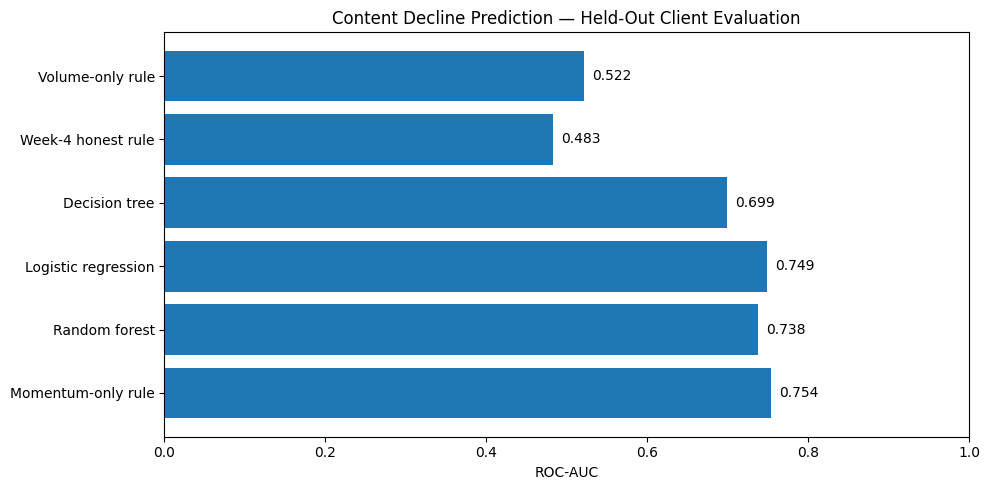

In [3]:

import pandas as pd
import matplotlib.pyplot as plt

# Aggregate results reported in the ML-11 research paper.
# These are transcribed results, not freshly rerun experiments.

results = pd.DataFrame({
    "Method": [
        "Volume-only rule",
        "Week-4 honest rule",
        "Decision tree",
        "Logistic regression",
        "Random forest",
        "Momentum-only rule"
    ],
    "ROC-AUC": [
        0.522, 0.483, 0.699,
        0.749, 0.738, 0.754
    ],
    "Average Precision": [
        0.381, 0.361, 0.563,
        0.644, 0.632, None
    ],
    "Precision@500": [
        0.410, 0.296, 0.876,
        0.882, 0.864, 0.874
    ]
})

print("FLYRANK ML-11 — HELD-OUT EVALUATION")
print("Evaluation month: March 2026")
print("Held-out content items: 24,886")
print("Held-out clients: 10")
print("Decline base rate: 36.9%")

display(results)

# Create the comparison chart.
fig, ax = plt.subplots(figsize=(10, 5))

bars = ax.barh(
    results["Method"],
    results["ROC-AUC"]
)

ax.invert_yaxis()
ax.set_xlim(0, 1)
ax.set_xlabel("ROC-AUC")
ax.set_title(
    "Content Decline Prediction — "
    "Held-Out Client Evaluation"
)

for bar, value in zip(bars, results["ROC-AUC"]):
    ax.text(
        value + 0.01,
        bar.get_y() + bar.get_height() / 2,
        f"{value:.3f}",
        va="center"
    )

plt.tight_layout()
plt.show()


**Figure interpretation.** On the client-grouped held-out evaluation, the momentum-only ranking achieved the highest reported ROC-AUC (0.754), slightly exceeding logistic regression (0.749). Logistic regression achieved the highest reported precision among the top 500 ranked content items (0.882). These findings suggest that interpretable early-month momentum signals may provide a useful baseline for editorial prioritization. However, the small performance differences and single-month evaluation do not establish that one method will consistently outperform the others in future periods.

*Source: Aggregate evaluation metrics reported in the ML-11 research paper. This figure reproduces reported results rather than independently rerunning model training.*

## Research visualization — model performance on the held-out clients

The two figures below reconstruct the reported held-out metrics using public-safe aggregate values. The volume-only and Week-4 honest rules are valid non-leaky baselines. The retrospective Week-4 steep-decline rule that uses later-month information is deliberately excluded.

**Interpretation:** Momentum-only ranking slightly exceeds logistic regression in ROC-AUC (0.754 vs 0.749) on this split, but logistic regression ranks four additional true declines among the top 500 (441 vs 437, based on reported precision). Differences on a single split should not be interpreted as definitive superiority.

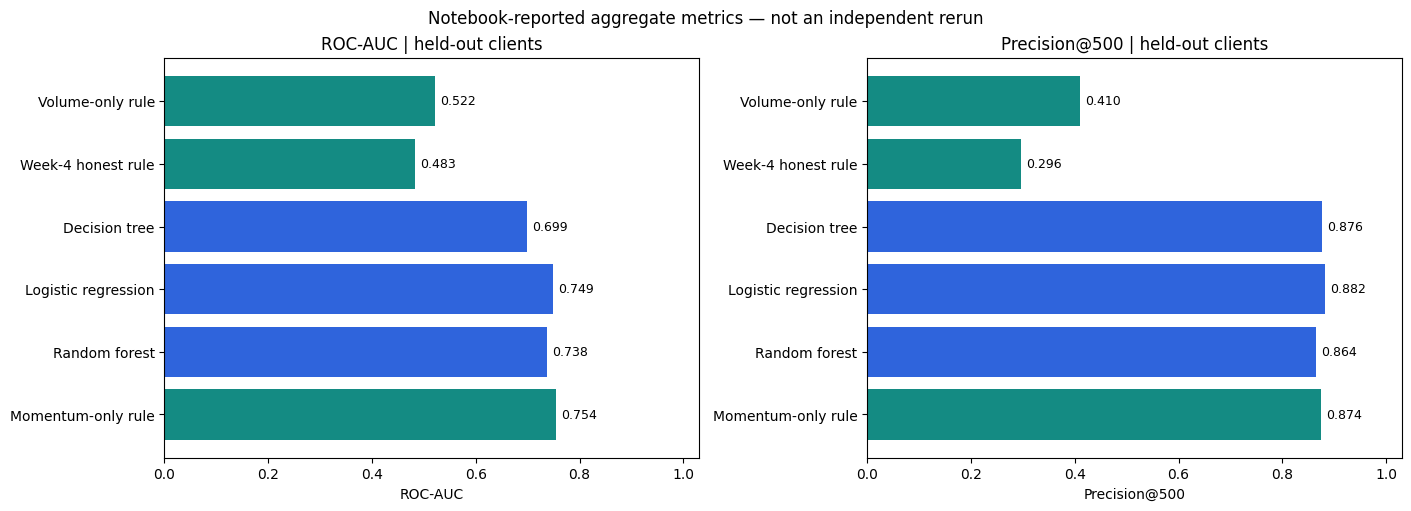

In [4]:
import matplotlib.pyplot as plt
import numpy as np

methods = ['Volume-only rule', 'Week-4 honest rule', 'Decision tree',
           'Logistic regression', 'Random forest', 'Momentum-only rule']
roc_auc = [0.522, 0.483, 0.699, 0.749, 0.738, 0.754]
precision_500 = [0.410, 0.296, 0.876, 0.882, 0.864, 0.874]
fig, axes = plt.subplots(1, 2, figsize=(14, 5), constrained_layout=True)
for ax, values, title in zip(
    axes, [roc_auc, precision_500],
    ['ROC-AUC | held-out clients', 'Precision@500 | held-out clients']
):
    ypos = np.arange(len(methods))
    bars = ax.barh(ypos, values, color=['#148b83']*2 + ['#2f64dc']*3 + ['#148b83'])
    ax.set_yticks(ypos, methods)
    ax.invert_yaxis()
    ax.set_xlim(0, 1.03)
    ax.set_xlabel(title.split('|')[0].strip())
    ax.set_title(title)
    for bar, value in zip(bars, values):
        ax.text(value + 0.01, bar.get_y()+bar.get_height()/2,
                f'{value:.3f}', va='center', fontsize=9)
plt.suptitle('Notebook-reported aggregate metrics — not an independent rerun')
plt.show()

## ML-12 — Five-minute research showcase outline

**0:00–0:45 | The editorial problem and research question.**  
FlyRank's content teams cannot manually inspect every page every day. A useful decision-support system should identify pages worth reviewing *before* a decline is observed, without pretending to know which edits will increase traffic. Research question: can early-month search-performance signals prioritize content at risk of a later-month impressions decline?

**0:45–1:45 | Data, labels, and methodology.**  
The March 2026 content-performance analysis includes 92,548 content items across 40 clients. Features are restricted to days 1–15; the retrospective outcome compares impressions in days 16–31 with days 1–15 and labels a decline when the later total is below 80% of the earlier total. Models were trained on 67,662 items from 30 clients and tested on 24,886 items from 10 previously unseen clients. Explain why separating clients is more credible than randomly splitting rows from the same client.

**1:45–3:00 | Show one comparison chart.**  
Display the held-out ROC-AUC figure. The volume-only rule reached 0.522, logistic regression reached 0.749, and a transparent momentum-only rule reached 0.754. The notable finding is not that momentum is universally superior, but that a simple interpretable signal was competitive with a trained classifier in this particular evaluation.

**3:00–4:00 | One honest result and its limits.**  
Logistic regression achieved precision@500 of 0.882 (441 of 500 candidates), versus 0.874 for momentum (437 of 500), against a 36.9% held-out decline base rate. The result is observational, based on one month, and may not transfer to future periods or different client mixes. The top-500 review queue was concentrated in a few large clients.

**4:00–5:00 | Practical recommendation and close.**  
Use a ranked review queue to focus analysts' time, inspect intent and search presentation, and require human approval before any content change. Next evaluate prospectively on future months, assess per-client fairness and capacity constraints, and monitor performance drift. Close: *The value of this work is disciplined editorial prioritization, not automated claims of traffic growth.*

**Suggested showcase visual:** the ROC-AUC bar chart above, with the base rate and held-out split noted below it.

## ML-12 — Two shareable research summaries

### A. Short social post

📊 **Can early search-performance signals help editorial teams decide what to review first?**

During my FlyRank ML Internship, I studied 92,548 content-item observations from March 2026 and compared transparent ranking rules with machine-learning classifiers.

Using a client-grouped held-out evaluation, a simple momentum-only rule achieved **ROC-AUC 0.754**, compared with **0.749** for logistic regression. The lesson: careful validation and interpretable baselines can matter as much as model complexity.

This is decision support for **human editorial review**, not proof that suggested edits will increase traffic.

📄 Research paper: https://yasmeenmh90-beep.github.io/flyrank-ml-internship-starter/

#MachineLearning #DataScience #Research #FlyRank

### B. Employer-facing summary — three sentences

I built and evaluated a content-decline prioritization workflow that compares interpretable ranking rules with decision trees, logistic regression, and random forests to support editorial review. The analysis used 92,548 March 2026 content-item observations from the FlyRank ML Internship dataset, with 24,886 items reserved for a client-grouped held-out evaluation. A momentum-only rule achieved ROC-AUC 0.754 while logistic regression achieved 88.2% precision among the top 500 review candidates, illustrating the potential of validated, human-supervised decision support without claiming causal traffic improvements.

### Research communication notes

- **Intended audience:** Editorial managers, applied ML practitioners, and prospective employers.
- **Public-safety:** Only aggregate counts and metrics are used; no client identifiers, page URLs, or private search queries are included.
- **Claim discipline:** This is a retrospective evaluation of ranking performance, not a prospective intervention or causal impact study.
- **Data credit:** Built on the [FlyRank ML Internship dataset](https://flyrank.ai).

## Self-check

Before you submit, confirm each line honestly:

- [x] Every section above is filled — markdown thinking AND the code that backs it
- [x] The notebook runs top to bottom with no errors (Runtime → Run all)
- [x] No client names, URLs, or private queries anywhere
- [x] My claims use careful words: observed, measured, directional, decision-support
- [x] Committed to my repo under `work/notebooks/` — then submit your repo URL on the card. Done.
- [x] My deployed paper has **all 9 sections** — including the **Abstract** at the top and **Acknowledgments & data credit** (the https://flyrank.ai link) at the bottom.
- [x] **ML-12 done in this notebook's closing cells:** 5-minute demo outline + a social-post cut + a 3-sentence employer-facing summary.
